# Track 1, Step 3: annotating the rare-variant VCF (snpEff + MyVariant.info + AlphaGenome)

**Input:** `data/track1_step2_rare_variants.vcf.gz` — the **591,339** variants that survive Step 2 (intrinsic QC + dbSNP Common subtraction).
**Output:**:

| File | What it adds | Script |
|---|---|---|
| `data/snpeff_annotated.vcf` (intermediate) | `GENE_SYMBOL`, `CONSEQUENCE`, `PUTATIVE_IMPACT`, etc. | `java -jar snpEff.jar` |
| `data/track1_step3a_snpeff_filter.vcf.gz` (intermediate) | `GNOMAD_AF`, `CADD_PHRED`, `REVEL`, `CLINVAR_SIG`, etc. | `notebooks/utils/track1_step3a_annotate.py` |
| `data/track1_step3_annotation_and_filtering.vcf.gz` | `AVI_PHRED`, `REGULATORY_FEATURE`, `AVI_STATUS` | `notebooks/utils/step3b_alphagenome.py` |

This notebook runs the VCF annotation and filtering pipeline (SnpEff, MyVariant.info, AlphaGenome), produces the final annotated VCF, and summarises the results.

See `docs/01-procedure.md` (Step 3) for the rationale behind every decision and `docs/02-findings.md` for the findings.

In [1]:
%%bash
cd ..
export PATH="$PWD/tools/env/bin:$PATH"
source .venv/bin/activate

if [ -f .env ]; then
    export $(grep -v '^#' .env | xargs)
fi

# 1. Functional annotation (SnpEff)
echo "Running SnpEff..."
java -Xmx8g -jar data/snpEff/snpEff.jar -canon -noStats GRCh38.99 data/track1_step2_rare_variants.vcf.gz > data/snpeff_annotated.vcf

# 2. Population & Clinical annotation (MyVariant.info)
echo "Running MyVariant.info annotation..."
python notebooks/utils/track1_step3a_annotate.py --input data/snpeff_annotated.vcf --output data/track1_step3a_snpeff_filter.vcf.gz

# 3. AlphaGenome Atlas scoring
echo "Running AlphaGenome annotation..."
python notebooks/utils/step3b_alphagenome.py --input data/track1_step3a_snpeff_filter.vcf.gz --output data/track1_step3_annotation_and_filtering.vcf.gz

# 4. Clean up intermediate files
echo "Pipeline complete! Final output saved to data/track1_step3_annotation_and_filtering.vcf.gz"


Running SnpEff...
Running MyVariant.info annotation...
[+] Annotating data/snpeff_annotated.vcf -> data/track1_step3a_snpeff_filter.vcf.gz
    batches of 1000, 4 in parallel
    annotated 905 variants (45/s)

[OK] 591,339 variants read, 905 HIGH/MODERATE annotated in 0.3 min
     Result: data/track1_step3a_snpeff_filter.vcf.gz
Running AlphaGenome annotation...
[+] Enriching data/track1_step3a_snpeff_filter.vcf.gz -> data/track1_step3_annotation_and_filtering.vcf.gz
    100 variants (35.3/s) | scored 86 | unscored 14
    200 variants (35.7/s) | scored 176 | unscored 24
    300 variants (38.1/s) | scored 250 | unscored 50
    400 variants (37.8/s) | scored 338 | unscored 62
    500 variants (38.9/s) | scored 412 | unscored 88
    600 variants (39.7/s) | scored 490 | unscored 110
    700 variants (39.6/s) | scored 572 | unscored 128
    800 variants (40.3/s) | scored 641 | unscored 159
    900 variants (40.7/s) | scored 714 | unscored 186

[OK] Step 3B: 905 variants written, 719 with AVI,

In [2]:
import gzip, re
from collections import Counter
from pathlib import Path

import pandas as pd

# The notebook runs with notebooks/notebook/ as cwd (repo convention: paths relative to the root via ../..)
REPO = Path.cwd()
while not (REPO / "docs" / "01-procedure.md").exists():
    REPO = REPO.parent

STEP2   = REPO / "data" / "track1_step2_rare_variants.vcf.gz"
SNPEFF  = REPO / "data" / "snpeff_annotated.vcf"
STEP3A  = REPO / "data" / "track1_step3a_snpeff_filter.vcf.gz"
STEP3B  = REPO / "data" / "track1_step3_annotation_and_filtering.vcf.gz"

for p in (STEP2, SNPEFF, STEP3A, STEP3B):
    print(f"{'OK ' if p.exists() else 'MISSING'} {p.relative_to(REPO)}"
          + (f"  ({p.stat().st_size/1e6:.1f} MB)" if p.exists() else ""))

OK  data/track1_step2_rare_variants.vcf.gz  (27.3 MB)
OK  data/snpeff_annotated.vcf  (240.7 MB)
OK  data/track1_step3a_snpeff_filter.vcf.gz  (0.1 MB)
OK  data/track1_step3_annotation_and_filtering.vcf.gz  (0.1 MB)


## Reading helpers

The output VCFs are text (plain gzip, not bgzip), so they are read with `gzip` and each line is split on tabs. The `INFO` field (column 8) is `key=value;key=value;…`; we turn it into a dict per variant. We never load the 591k snpEff variants into memory as a DataFrame: we only count what is needed while streaming.

In [3]:
def iter_vcf(path):
    # Yields (chrom, pos, ref, alt, info_dict, sample_fields) per variant, skipping the header.
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            p = line.rstrip("\n").split("\t")
            info = {}
            for kv in p[7].split(";"):
                k, sep, v = kv.partition("=")
                info[k] = v if sep else True
            yield p[0], int(p[1]), p[3], p[4], info, p[9:]

def first_ann(info):
    # snpEff writes ANN=alt|consequence|impact|gene|…; with -canon the first entry is the canonical transcript.
    ann = info.get("ANN")
    if not ann:
        return None
    return ann.split(",", 1)[0].split("|")

def zygosity(sample):
    gt = sample[0].split(":")[0].replace("|", "/")
    a = gt.split("/")
    if "." in a: return "UNKNOWN"
    if set(a) == {"0"}: return "HOM_REF"
    return "HOM_ALT" if len(set(a)) == 1 else "HET"

def fnum(x):
    try: return float(x)
    except (TypeError, ValueError): return None

## 3.1 — snpEff: what is the impact of the 591,339 rare variants?

snpEff assigns each variant a **consequence** (missense, stop_gained, intron_variant, …) and an **impact** on four levels:

| Impact | Meaning | Examples |
|---|---|---|
| `HIGH` | Almost certainly breaks the protein | stop_gained, frameshift, splice_donor/acceptor |
| `MODERATE` | Changes the protein, effect uncertain | missense, inframe_insertion/deletion |
| `LOW` | Probably harmless | synonymous_variant |
| `MODIFIER` | Outside the coding region | intron_variant, intergenic, UTR |

The `-canon` flag forces a single transcript (the canonical one) per gene, so every variant gets **one** annotation instead of one per isoform. Without it the output multiplies and the impact counts inflate.

Per `docs/00-references.md` §3, ~85 % of known pathogenic Mendelian variants sit in exons or splice sites, so the pipeline keeps `HIGH` + `MODERATE`.

In [4]:
impact_counts, consequence_counts = Counter(), Counter()
total = 0
for chrom, pos, ref, alt, info, _ in iter_vcf(SNPEFF):
    total += 1
    ann = first_ann(info)
    if ann is None:
        impact_counts["(no ANN)"] += 1
        continue
    impact_counts[ann[2]] += 1
    if ann[2] in ("HIGH", "MODERATE"):
        consequence_counts[ann[1]] += 1

print(f"Variants annotated by snpEff: {total:,}")
filtered_out = impact_counts.get('LOW', 0) + impact_counts.get('MODIFIER', 0)
print(f"Variants explicitly filtered out (LOW + MODIFIER): {filtered_out:,} ({filtered_out/total*100:.2f}%)")

impact_df = (pd.Series(impact_counts, name="variants").rename_axis("impact")
             .reindex(["HIGH", "MODERATE", "LOW", "MODIFIER", "(no ANN)"]).dropna().astype(int).to_frame())
impact_df["%"] = (impact_df["variants"] / total * 100).round(2)
impact_df

Variants annotated by snpEff: 591,339
Variants explicitly filtered out (LOW + MODIFIER): 590,434 (99.85%)


,variants,%
impact,,
HIGH,128,0.02
MODERATE,777,0.13
LOW,769,0.13
MODIFIER,589665,99.72


Reading: practically everything that survives Step 2 is `MODIFIER` (intronic/intergenic). The protein-altering candidates are about **1,500**, not the 10–20k the procedure estimated. Steps 4 and 5 therefore work on a small set, and every additional annotation (gnomAD, CADD, ClinVar, AVI) carries a lot of weight.

Consequences within HIGH/MODERATE:

In [5]:
pd.Series(consequence_counts, name="variants").sort_values(ascending=False).to_frame()

,variants
missense_variant,681
frameshift_variant,74
disruptive_inframe_deletion,40
disruptive_inframe_insertion,19
stop_gained,16
missense_variant&splice_region_variant,15
splice_acceptor_variant&intron_variant,12
conservative_inframe_insertion,12
conservative_inframe_deletion,10
frameshift_variant&splice_region_variant,4


## 3.2 — MyVariant.info: population frequency, in-silico pathogenicity and ClinVar

`track1_step3a_annotate.py` takes the HIGH/MODERATE variants and asks MyVariant.info, in batches of 1,000 HGVS ids (`chr11:g.5227002T>A`, HBB rs334 as an example), for these fields:

| INFO tag | MyVariant field | Purpose |
|---|---|---|
| `GNOMAD_AF` / `GNOMAD_EXOME_AF` | `gnomad_genome.af.af` / `gnomad_exome.af.af` | Frequency in the general population: a variant causing an ultra-rare disease cannot be common |
| `CADD_PHRED` | `dbnsfp.cadd.phred` | Deleteriousness score (≥20 = top 1 % of the genome) |
| `REVEL` | `dbnsfp.revel.score` | Missense pathogenicity (≥0.5 suggests pathogenic) |
| `CLINVAR_SIG`, `CLINVAR_REVIEW_STATUS` | `clinvar.rcv.*` | Clinical classification already reported |
| `OMIM_PHENOTYPE` | `clinvar.rcv.conditions.identifiers.omim` | OMIM disease linked to the ClinVar record |

**Two details that cost a whole run:**

1. **`assembly=hg38` is mandatory.** MyVariant searches hg19 by default. With GRCh38 coordinates and no such parameter, 1,619 of 1,653 variants came back "notfound" and the 34 "found" were *other* variants that share a coordinate in hg19. Any output produced before this fix is invalid.
2. **Indels need valid HGVS.** `g.100AT>A` is not HGVS; it must be `g.101del`, `g.100_101insCCT`, `g.101_102delinsCC`. The script now does that.

The requested fields also changed: `cadd.phred` exists only in hg19 (in hg38 it comes via dbNSFP) and `LoFtool` does not exist in MyVariant, so `LOFTOOL_SCORE` is no longer emitted.

### Annotation coverage

In [6]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3A):
    rows.append({
        "gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"), "consequence": info.get("CONSEQUENCE"),
        "type": "SNV" if len(ref) == 1 and len(alt.split(",")[0]) == 1 else "indel",
        "zygosity": zygosity(sample),
        "hit": "MYVARIANT_HIT" in info,
        "gnomad_af": fnum(info.get("GNOMAD_AF")), "gnomad_exome_af": fnum(info.get("GNOMAD_EXOME_AF")),
        "cadd": fnum(info.get("CADD_PHRED")), "revel": fnum(info.get("REVEL")),
        "clinvar": info.get("CLINVAR_SIG"), "omim": info.get("OMIM_PHENOTYPE"),
    })
a3 = pd.DataFrame(rows)
print(f"HIGH/MODERATE variants in the 3A output: {len(a3):,}  "
      f"(SNV {int((a3['type']=='SNV').sum()):,}, indel {int((a3['type']=='indel').sum()):,})")

coverage = pd.DataFrame({
    "with value": [a3.hit.sum(), a3.gnomad_af.notna().sum(), a3.gnomad_exome_af.notna().sum(),
                   a3.cadd.notna().sum(), a3.revel.notna().sum(), a3.clinvar.notna().sum(), a3.omim.notna().sum()],
}, index=["MYVARIANT_HIT", "GNOMAD_AF", "GNOMAD_EXOME_AF", "CADD_PHRED", "REVEL", "CLINVAR_SIG", "OMIM_PHENOTYPE"])
coverage[f"% of {len(a3):,}"] = (coverage["with value"] / len(a3) * 100).round(1)
coverage

HIGH/MODERATE variants in the 3A output: 905  (SNV 719, indel 186)


,with value,% of 905
MYVARIANT_HIT,905,100.0
GNOMAD_AF,878,97.0
GNOMAD_EXOME_AF,683,75.5
CADD_PHRED,629,69.5
REVEL,507,56.0
CLINVAR_SIG,171,18.9
OMIM_PHENOTYPE,56,6.2


REVEL only exists for missense variants (hence ~860 rather than 1,653) and ClinVar only for variants someone has reported: those gaps are expected, not failures.

### The important finding: dbSNP Common is not enough as a frequency filter

Step 2 subtracts the variants in `common_all_20180418.vcf.gz` (dbSNP b151, 2018). Let us look at the gnomAD frequency of the variants that **passed** that filter:

In [7]:
def af_bin(af):
    if af is None: return "no gnomAD data"
    if af > 0.05:  return "> 5 %  (common)"
    if af > 0.01:  return "1-5 %  (common)"
    if af > 0.001: return "0.1-1 %"
    return "< 0.1 % (rare)"

a3["af_bin"] = a3.gnomad_af.map(af_bin)
order = ["> 5 %  (common)", "1-5 %  (common)", "0.1-1 %", "< 0.1 % (rare)", "no gnomAD data"]
tab = pd.crosstab(a3.af_bin, a3.type).reindex(order).fillna(0).astype(int)
tab["total"] = tab.sum(axis=1)
common = int((a3.gnomad_af > 0.01).sum())
print(f"{common:,} of {len(a3):,} 'rare' variants have gnomAD AF > 1 %  ({common/len(a3)*100:.0f} %)")
tab

712 of 905 'rare' variants have gnomAD AF > 1 %  (79 %)


type,SNV,indel,total
af_bin,,,
> 5 % (common),530,157,687
1-5 % (common),13,12,25
0.1-1 %,52,5,57
< 0.1 % (rare),124,12,136
no gnomAD data,0,0,0


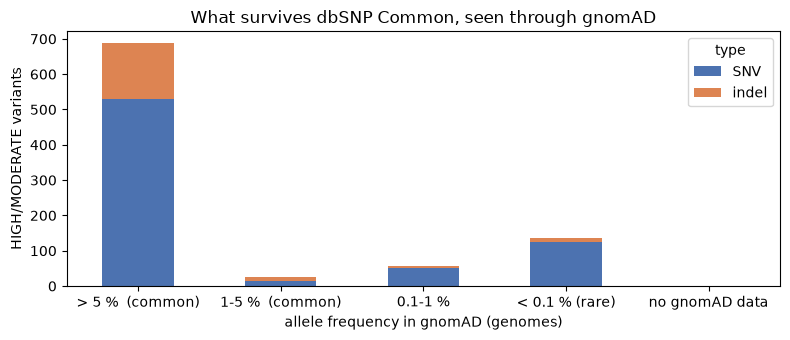

In [8]:
import matplotlib.pyplot as plt

ax = tab.drop(columns="total").plot.bar(stacked=True, figsize=(8, 3.5), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("HIGH/MODERATE variants")
ax.set_xlabel("allele frequency in gnomAD (genomes)")
ax.set_title("What survives dbSNP Common, seen through gnomAD")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

We checked a sample of 300 of those common SNVs against the local dbSNP with `tabix`: **none was in the file**. This is not a key bug in `run_step2_prefilter.py`; the 2018 blacklist simply does not contain most of the coding variants gnomAD flags as common (including cases where the reference genome carries the minor allele, AF ≈ 0.9999). Indels are worse because dbSNP normalises them differently (278 of 307 are common).

**Consequence for the team:** the effective frequency filter is `GNOMAD_AF` from Step 3A. Step 5 discards AF > 1 % (`--max-af 0.01`, the same threshold the procedure justifies; it is not lowered because of the founder-effect caution in `00-references.md` §4). The structural fix would be to replace dbSNP Common with a gnomAD blacklist in Step 2.

### ClinVar: what it says about what is already reported

In [9]:
clin = a3.clinvar.dropna().str.split("|").explode().str.replace("_", " ").value_counts().to_frame("variants")
clin

,variants
clinvar,
Benign,87
Uncertain significance,56
Likely benign,36
Pathogenic,8
Benign/Likely benign,7
Conflicting interpretations of pathogenicity,4
Likely pathogenic,4
drug response,3
not provided,3


## 3.3 — AlphaGenome Atlas: AVI scoring

`step3b_alphagenome.py` asks the AlphaGenome Atlas for two *scorers* per variant:

* **`AVI_SCORE`**: AlphaGenome Variant Impact, a unified molecular-impact score. It comes with a quantile calibrated against all genome-wide SNVs; we convert it to **`AVI_PHRED` = −10·log10(1 − quantile)**, the same scale as CADD: ≥20 is the top 1 % of the genome, ≥30 the top 0.1 %.
* **`AVI_SCORE_FEATURE_IMPORTANCE`**: 18 modalities (splicing, AlphaMissense, Cactus/phastCons conservation, RNA-seq, DNase, …). We keep the one with the largest attribution in **`REGULATORY_FEATURE`**: it says *why* the model believes the variant matters.

Limitations discovered against the live API (alphagenome 0.9.0):

* **SNVs only.** Every indel returns `NotImplementedError`; the script marks them `AVI_STATUS=indel_unsupported` without spending a call.
* The server validates the REF allele against GRCh38 and one error fails the whole batch; the script retries variant by variant and marks `ref_mismatch`.
* `TARGET_GENE`, planned in the procedure, is not returned by these scorers: the gene remains snpEff's `GENE_SYMBOL`.
* It is a **research** tool: a high AVI is predicted molecular impact, not a diagnosis.

In [10]:
rows = []
for chrom, pos, ref, alt, info, sample in iter_vcf(STEP3B):
    rows.append({"gene": info.get("GENE_SYMBOL"), "impact": info.get("PUTATIVE_IMPACT"),
                 "status": info.get("AVI_STATUS"), "avi_phred": fnum(info.get("AVI_PHRED")),
                 "feature": info.get("REGULATORY_FEATURE")})
b3 = pd.DataFrame(rows)
print(f"Variants in the 3.2 output: {len(b3):,}")
print(b3.status.value_counts().to_string(), "\n")
scored = b3.dropna(subset=["avi_phred"])
print(f"AVI_PHRED >= 20 (genome-wide top 1 %): {int((scored.avi_phred>=20).sum())}   "
      f">= 30 (top 0.1 %): {int((scored.avi_phred>=30).sum())}")
pd.crosstab(b3.feature.fillna("(no score)"), b3.impact).sort_values("MODERATE", ascending=False)

Variants in the 3.2 output: 905
status
ok                   719
indel_unsupported    186 

AVI_PHRED >= 20 (genome-wide top 1 %): 151   >= 30 (top 0.1 %): 10


impact,HIGH,MODERATE
feature,,
ALPHAMISSENSE,0,314
CACTUS_241_WAY,3,314
(no score),105,81
PHASTCONS_470_WAY,2,38
MERGED_SPLICING,1,21
MAX_ABS_DNASE,0,5
MAX_ABS_RNA_SEQ,0,2
MAX_ABS_CHIP_HISTONE,0,2
PROTEIN_TERMINATION,14,0


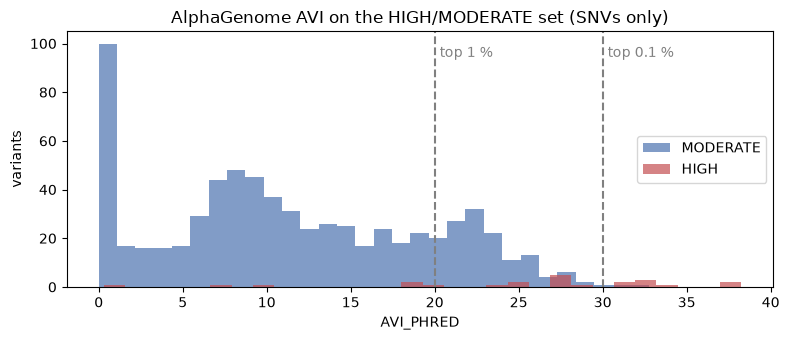

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for imp, color in (("MODERATE", "#4C72B0"), ("HIGH", "#C44E52")):
    ax.hist(scored.loc[scored.impact == imp, "avi_phred"], bins=30, alpha=0.7, label=imp, color=color)
for x, lab in ((20, "top 1 %"), (30, "top 0.1 %")):
    ax.axvline(x, ls="--", color="grey"); ax.text(x + 0.3, ax.get_ylim()[1] * 0.9, lab, color="grey")
ax.set_xlabel("AVI_PHRED"); ax.set_ylabel("variants"); ax.set_title("AlphaGenome AVI on the HIGH/MODERATE set (SNVs only)")
ax.legend(); plt.tight_layout(); plt.show()

Reading: the dominant modality for coding variants is **conservation** (`CACTUS_241_WAY`) followed by **AlphaMissense**; splicing and protein termination appear in the HIGH set. Because AVI and CADD share the Phred scale, Step 5 can use them together as in-silico evidence.

In [12]:
import os
print("Cleaning up intermediate files to leave only the final VCF...")
if SNPEFF.exists():
    os.remove(SNPEFF)
if STEP3A.exists() and STEP3A != STEP3B:
    os.remove(STEP3A)
print("Done.")

Cleaning up intermediate files to leave only the final VCF...
Done.
